# Predicting High-Selling Video Games
### Team Members
### Carlos Olvera, Chris Mathews, Jared Baron Panares, Carlos Galindo

### The Problem trying to solve
### 1. Introduction

Our goal is to predict whether a video game will be a high-selling
title based on information about the game.

### Prediction: High-selling game prediction — Classification

We define a high-selling game as a game that sells at least
1 million copies globally.

Target:
- 1 = High-Selling (≥ 1 million copies)
- 0 = Not High-Selling (< 1 million copies)

We will compare K-Nearest Neighbors and Decision Tree classifiers.

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

## Part 1: Initial Data Exploration

In [2]:
videogame_df = pd.read_csv("VideoGameAnalysis-2024.csv")
videogame_df.head()
original_df = videogame_df.copy()

In [3]:
# Initial Data Exploration
videogame_df.shape
videogame_df.info()
videogame_df.describe(include="all")

<class 'pandas.DataFrame'>
RangeIndex: 64016 entries, 0 to 64015
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   img           64016 non-null  str    
 1   title         64016 non-null  str    
 2   console       64016 non-null  str    
 3   genre         64016 non-null  str    
 4   publisher     64016 non-null  str    
 5   developer     63999 non-null  str    
 6   critic_score  6678 non-null   float64
 7   total_sales   18922 non-null  float64
 8   na_sales      12637 non-null  float64
 9   jp_sales      6726 non-null   float64
 10  pal_sales     12824 non-null  float64
 11  other_sales   15128 non-null  float64
 12  release_date  56965 non-null  str    
 13  last_update   17879 non-null  str    
dtypes: float64(6), str(8)
memory usage: 13.6 MB


,img,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update
count,64016,64016,64016,64016,64016,63999,6678.000000,18922.000000,12637.000000,6726.000000,12824.000000,15128.000000,56965,17879
unique,56177,39798,81,20,3383,8862,NaN,NaN,NaN,NaN,NaN,NaN,7922,1545
top,/games/boxart/default.jpg,Plants vs. Zombies,PC,Misc,Unknown,Unknown,NaN,NaN,NaN,NaN,NaN,NaN,1994-01-01,2018-01-06
freq,7810,17,12617,9304,8842,4435,NaN,NaN,NaN,NaN,NaN,NaN,515,165
mean,NaN,NaN,NaN,NaN,NaN,NaN,7.220440,0.349113,0.264740,0.102281,0.149472,0.043041,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,1.457066,0.807462,0.494787,0.168811,0.392653,0.126643,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,6.400000,0.030000,0.050000,0.020000,0.010000,0.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,7.500000,0.120000,0.120000,0.040000,0.040000,0.010000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,8.300000,0.340000,0.280000,0.120000,0.140000,0.030000,NaN,NaN


In [4]:
#Examine missing values
missing = pd.DataFrame({
    "Missing Count": videogame_df.isnull().sum(),
    "Missing Percent": videogame_df.isnull().mean() * 100
})

missing.sort_values("Missing Percent", ascending=False)

,Missing Count,Missing Percent
critic_score,57338,89.568233
jp_sales,57290,89.493252
na_sales,51379,80.259623
pal_sales,51192,79.967508
other_sales,48888,76.368408
last_update,46137,72.071045
total_sales,45094,70.441765
release_date,7051,11.014434
developer,17,0.026556
publisher,0,0.000000


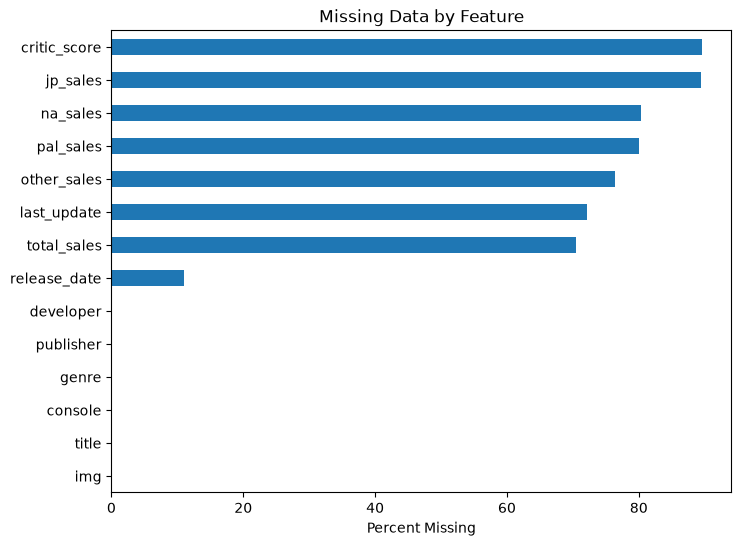

In [5]:
missing["Missing Percent"].sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Percent Missing")
plt.title("Missing Data by Feature")
plt.show()

In [6]:
#inspect category counts
print(f"Genre: {videogame_df['genre'].value_counts().shape[0]}")
print(f"Console: {videogame_df['console'].value_counts().shape[0]}")
print(f"Publisher: {videogame_df['publisher'].nunique()}")
print(f"Developer: {videogame_df['developer'].nunique()}")

Genre: 20
Console: 81
Publisher: 3383
Developer: 8862


# Part 2: Data Cleaning


### Target Variable Creation

We use total_sales to determine whether each historical game was
high-selling. Games with missing total_sales cannot be labeled and
are therefore removed.

After creating the Labels, total_sales is removed from the predictors
to prevent data leakage.

Done so total_sales feature will not dominate prediction

In [7]:
videogame_df = videogame_df.dropna(subset=["total_sales"])

videogame_df["label_highselling"] = (
    videogame_df["total_sales"] >= 1.0
).astype(int)

In [8]:
videogame_df["label_highselling"].value_counts()
videogame_df["label_highselling"].value_counts(normalize=True) * 100

label_highselling
0    92.046295
1     7.953705
Name: proportion, dtype: float64

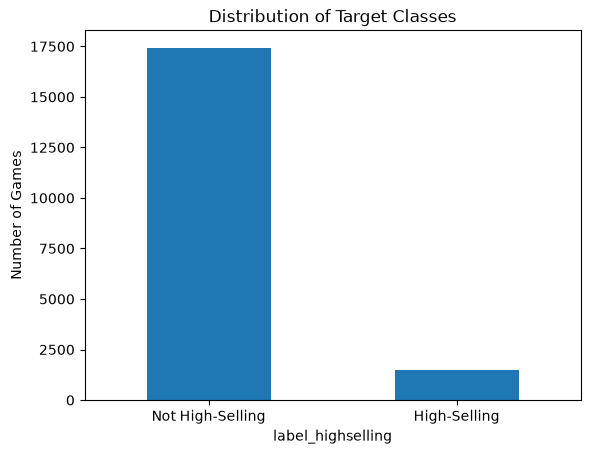

In [9]:
videogame_df["label_highselling"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xticks([0, 1], ["Not High-Selling", "High-Selling"], rotation=0)
plt.ylabel("Number of Games")
plt.title("Distribution of Target Classes")
plt.show()

The graph because it shows the 92% vs. 8% imbalance

In [10]:
videogame_df = videogame_df.drop(
    columns=[
        "img",
        "total_sales",
        "na_sales",
        "jp_sales",
        "pal_sales",
        "other_sales"
    ]
)

# game_titles = original_df.loc[videogame_df.index, "title"]


In [11]:

#Examine missing values
missing = pd.DataFrame({
    "Missing Count": videogame_df.isnull().sum(),
    "Missing Percent": videogame_df.isnull().mean() * 100
})

missing.sort_values("Missing Percent", ascending=False)

,Missing Count,Missing Percent
last_update,14903,78.760173
critic_score,14796,78.194694
release_date,90,0.475637
developer,4,0.021139
title,0,0.000000
publisher,0,0.000000
genre,0,0.000000
console,0,0.000000
label_highselling,0,0.000000


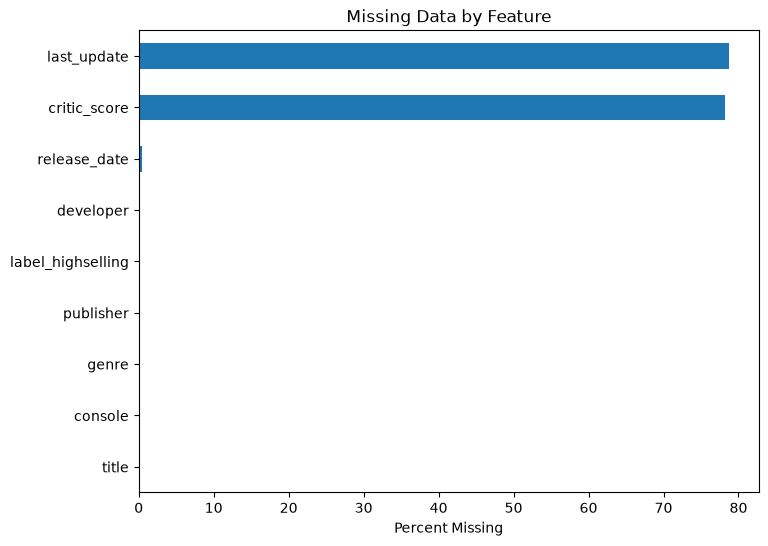

In [12]:
missing["Missing Percent"].sort_values().plot(
    kind="barh",
    figsize=(8, 6)
)

plt.xlabel("Percent Missing")
plt.title("Missing Data by Feature")
plt.show()

In [13]:
print(videogame_df.head())

# Feartures to use for modeling
features = [
    "title",
    "console",
    "genre",
    "publisher",
    #"developer",
    "critic_score",
    "release_date",
    "label_highselling"
]

videogame_df = videogame_df[features]

                         title console    genre       publisher  \
0           Grand Theft Auto V     PS3   Action  Rockstar Games   
1           Grand Theft Auto V     PS4   Action  Rockstar Games   
2  Grand Theft Auto: Vice City     PS2   Action  Rockstar Games   
3           Grand Theft Auto V    X360   Action  Rockstar Games   
4    Call of Duty: Black Ops 3     PS4  Shooter      Activision   

        developer  critic_score release_date last_update  label_highselling  
0  Rockstar North           9.4   2013-09-17         NaN                  1  
1  Rockstar North           9.7   2014-11-18  2018-01-03                  1  
2  Rockstar North           9.6   2002-10-28         NaN                  1  
3  Rockstar North           NaN   2013-09-17         NaN                  1  
4        Treyarch           8.1   2015-11-06  2018-01-14                  1  


### Duplicate Records
There were 12 duplicates, we reduced it to 0 so there would not be any unneeded data

In [14]:
duplicate_count = videogame_df.duplicated().sum()
videogame_df = videogame_df.drop_duplicates()
print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 21


In [15]:
duplicate_count = videogame_df.duplicated().sum()
print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


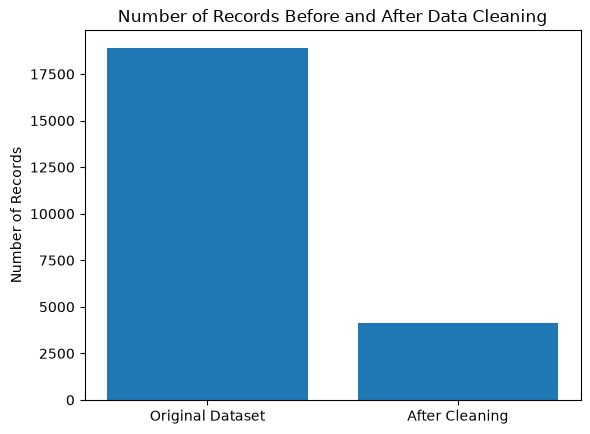

In [16]:
#The amount of records we are going to use after removing unnecessary columns and dropping rows with missing values
original_records = len(videogame_df)

# Remove any row that has at least one missing value
videogame_df = videogame_df.dropna()

remaining_records = len(videogame_df)

# Compare the number of records before and after data cleaning

plt.bar(
    ["Original Dataset", "After Cleaning"],
    [original_records, remaining_records]
)

plt.title("Number of Records Before and After Data Cleaning")
plt.ylabel("Number of Records")

plt.show()

## Part 3: Feature Engineering
We want to see if there are any categorical features that we have to one-hot encode

We are going to one-hot encode the categorical features, which are console, genre, and publisher

In [17]:
categorical_cols = ["console", "genre", "publisher"]

# checking for the number of unique values of these features
print(videogame_df[categorical_cols].nunique())

# console and genre have a lower amount of unique values, so we can just fully one-hot encode

# however, publisher has 213 unique values, so instead we are going to restrict this to 50

# which publishers are in the top 50 most frequent publishers
fifty_top_publishers = (videogame_df["publisher"].value_counts().head(50))

# how many of the 4123 records have these top 50 publishers
publisher_count = videogame_df["publisher"].isin(fifty_top_publishers.index).sum()
total = videogame_df.shape[0]
print(f"Publishers: {publisher_count}/{total} ({publisher_count / total * 100:.2f}%)")

# For the categorical features, this leaves us with
# 28 columns for console
# 20 columns for genre
# 51 columns for publishers (the top 50, plus the 'other' column)



# Replace publishers outside the top 50 with "Other"
videogame_df["publisher"] = videogame_df["publisher"].where(videogame_df["publisher"].isin(fifty_top_publishers.index),"Other")

# One-hot encode categorical features
videogame_df = pd.get_dummies(videogame_df, columns=categorical_cols, dtype=int)

# Check the resulting dimensions
print(videogame_df.shape)

console       28
genre         20
publisher    214
dtype: int64
Publishers: 3622/4123 (87.85%)
(4123, 103)


The remaining features to 'engineer' are the release_date and crtitic_score.

We are going to leave the critic_score as is, since it works as a numerical feature

The release_date will be adjusted to become numerical

In [18]:
# We want to split the month and year of the release_date feature into two features
# Our reasoning for this is that we believed that release month is dominant feature regarding game sells
# However, we still want to consider the year, in order to have the context of how video games were selling in that point in history

# Convert release_date to datetime
videogame_df["release_date"] = pd.to_datetime(videogame_df["release_date"])

# Extract month and year
videogame_df["release_month"] = videogame_df["release_date"].dt.month
videogame_df["release_year"] = videogame_df["release_date"].dt.year

# Drop the original release_date column
videogame_df = videogame_df.drop(columns=["release_date"])

## Part 4: Algorithm Selection
The first algorithm we chose was Decision Trees.

In [23]:
# Title must be dropped for training
videogame_labels = videogame_df['label_highselling']
videogame_features = videogame_df.drop(columns=['label_highselling','title'])

# We use the 80-20 split to separate our data into training and test sets.
X_train, X_test, y_train, y_test = train_test_split(videogame_features, videogame_labels, test_size=0.2, train_size=0.8)

# Verify the number of records in each.
print("Number of Training Records: " + str(len(X_train)))
print("Number of Test Records: " + str(len(X_test)))

# We can use the sci-kit learn DecisionTreeClassifier. We can then keep track of its accuracy.
decision_tree = DecisionTreeClassifier(criterion='entropy', max_depth=10)
decision_tree.fit(X_train, y_train)

prediction = decision_tree.predict(X_test)
accuracy = accuracy_score(y_test, prediction)
print("Accuracy Score: " + str(accuracy))

Number of Training Records: 3298
Number of Test Records: 825
Accuracy Score: 0.8315151515151515


Decision Tress have two hyperparameters that can be tuned to improve accuracy. These are the max depth of the tree (max_depth) and the minimum number of samples required to be at a leaf node (min_samples_leaf). First, we'll adjust the max_depth of the tree to determine the best depth from 1 to 21. We've set that range to make the training plateau easier to observe.

Depth 1- Training Accuracy: 0.8174651303820497
Depth 1- Training Accuracy: 0.806060606060606
Depth 2- Training Accuracy: 0.8174651303820497
Depth 2- Training Accuracy: 0.806060606060606
Depth 3- Training Accuracy: 0.8305033353547605
Depth 3- Training Accuracy: 0.8145454545454546
Depth 4- Training Accuracy: 0.8311097634930261
Depth 4- Training Accuracy: 0.8096969696969697
Depth 5- Training Accuracy: 0.845360824742268
Depth 5- Training Accuracy: 0.8303030303030303
Depth 6- Training Accuracy: 0.8562765312310491
Depth 6- Training Accuracy: 0.8096969696969697
Depth 7- Training Accuracy: 0.8641600970285022
Depth 7- Training Accuracy: 0.806060606060606
Depth 8- Training Accuracy: 0.8720436628259551
Depth 8- Training Accuracy: 0.8278787878787879
Depth 9- Training Accuracy: 0.8823529411764706
Depth 9- Training Accuracy: 0.8109090909090909
Depth 10- Training Accuracy: 0.8911461491813221
Depth 10- Training Accuracy: 0.833939393939394
Depth 11- Training Accuracy: 0.8996361431170407
Depth 11- Train

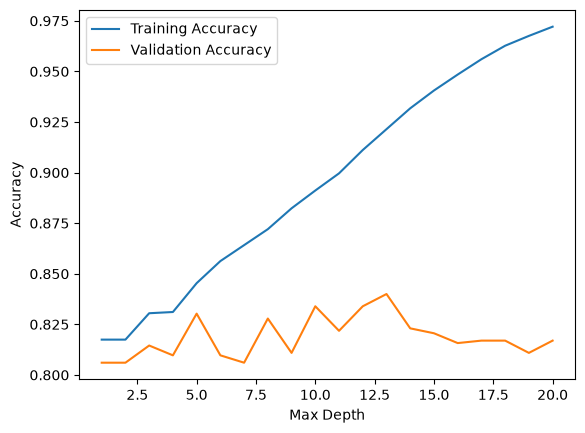

In [32]:
training_accuracies = []
testing_accuracies = []

for depth in range(1, 21):
    decision_tree = DecisionTreeClassifier(criterion='entropy', max_depth=depth)
    decision_tree.fit(X_train, y_train)

    training_prediction = decision_tree.predict(X_train)
    training_accuracy = accuracy_score(y_train, training_prediction)
    training_accuracies.append(training_accuracy)

    testing_prediction = decision_tree.predict(X_test)
    testing_accuracy = accuracy_score(y_test, testing_prediction)
    testing_accuracies.append(testing_accuracy)

    print("Depth " + str(depth) + "- Training Accuracy: " + str(training_accuracy))
    print("Depth " + str(depth) + "- Training Accuracy: " + str(testing_accuracy))

# We can see a visual of the accuracies here. We want to pick a validation accuracy that's highest
# while the depth is kept low.
plt.plot(range(1, 21), training_accuracies, label='Training Accuracy')
plt.plot(range(1, 21), testing_accuracies, label='Validation Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.legend()

Depth 20- Training Accuracy: 0.8908429351121893
Depth 20- Training Accuracy: 0.8266666666666667
Depth 20- Training Accuracy: 0.8729533050333536
Depth 20- Training Accuracy: 0.8460606060606061
Depth 20- Training Accuracy: 0.8632504548211037
Depth 20- Training Accuracy: 0.8290909090909091
Depth 20- Training Accuracy: 0.8599151000606429
Depth 20- Training Accuracy: 0.8363636363636363
Depth 20- Training Accuracy: 0.8465736810187993
Depth 20- Training Accuracy: 0.8327272727272728
Depth 20- Training Accuracy: 0.8371740448756823
Depth 20- Training Accuracy: 0.8254545454545454


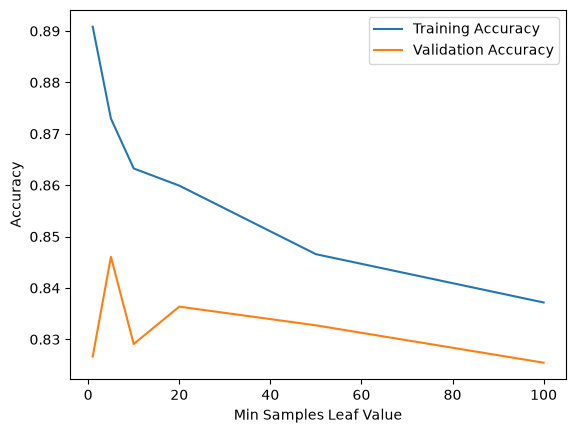

In [36]:
# We pick a set of leaf values that increases exponentially as smaller hyperparameter values are more 
# are more impactful for this value
min_samples_leaves = [1, 5, 10, 20, 50, 100] 
training_accuracies = []
testing_accuracies = []

for n in min_samples_leaves:
    decision_tree = DecisionTreeClassifier(criterion='entropy', max_depth=10, min_samples_leaf=n)
    decision_tree.fit(X_train, y_train)

    training_prediction = decision_tree.predict(X_train)
    training_accuracy = accuracy_score(y_train, training_prediction)
    training_accuracies.append(training_accuracy)

    testing_prediction = decision_tree.predict(X_test)
    testing_accuracy = accuracy_score(y_test, testing_prediction)
    testing_accuracies.append(testing_accuracy)

    print("Depth " + str(depth) + "- Training Accuracy: " + str(training_accuracy))
    print("Depth " + str(depth) + "- Training Accuracy: " + str(testing_accuracy))

# We can see a visual of the accuracies here. We want to pick a validation accuracy that's highest
# while the depth is kept low.
plt.plot(min_samples_leaves, training_accuracies, label='Training Accuracy')
plt.plot(min_samples_leaves, testing_accuracies, label='Validation Accuracy')
plt.xlabel('Min Samples Leaf Value')
plt.ylabel('Accuracy')
plt.legend()

We decided to pick a max_depth of [blank] and min_samples_leaf of [blank]

In [37]:
# Note adjust this when we decide which hyperparameters to pick
decision_tree = DecisionTreeClassifier(criterion='entropy', max_depth=10)
cross = cross_val_score(decision_tree, videogame_features, videogame_labels, cv=5)

print("Mean CV Accuracy: " + str(cross.mean()))
print("Standard Deviation: " + str(cross.std()))

Mean CV Accuracy: 0.8023312739040895
Standard Deviation: 0.026536232146010752
